# 423 – A qGAN on Real Data: Used-Car Prices

So far the data came from textbook distributions.  Real data is messier: skewed, with
outliers, and only a few hundred samples.  Here a qGAN learns the joint distribution of two
columns of a used-car sales dataset:

* `Present_Price` – the current ex-showroom price of the model (in lakh rupees),
* `Kms_Driven` – the distance the car has been driven (we use thousands of km).

**You will learn to** prepare real data for a qGAN – choose the columns, handle outliers and
pick a grid resolution – and judge the result honestly.

**Prerequisites:** `422`.

> This notebook runs entirely on the local simulator.  (An earlier version selected an IBM
> device here; a qGAN needs thousands of circuit evaluations, so train on a simulator.)

In [1]:
# === BACKEND SETUP (qiskit_backend_config) ===
# -----------------------------------------------
# Common backend helper — works with Qiskit 2.x / qiskit-aer / qiskit-ibm-runtime.
# Provides drop-in replacements for the removed Aer, BasicAer, execute(), and IBMQ.
#
# HOW TO SELECT A BACKEND
# -----------------------
# Simulator (default, runs locally — no credentials needed):
#   BACKEND_NAME = "qasm_simulator"        # shot-based measurements
#   BACKEND_NAME = "statevector_simulator" # full statevector
#   BACKEND_NAME = "unitary_simulator"     # full unitary matrix
#
# Real IBM hardware (requires IBM Quantum account):
#   Set the environment variable:  IBM_QUANTUM_TOKEN=<your_token>
#   Then choose a device, e.g.:
#   BACKEND_NAME = "ibm_brisbane"
#   BACKEND_NAME = "least_busy"  # auto-pick least-busy device
#
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from qiskit_backend_config import (get_backend, execute, Aer, BasicAer,
                                   IBMQ, least_busy, job_monitor, assemble, combine)

# ── Choose your backend here ──────────────────────────────────────────────
BACKEND_NAME = "qasm_simulator"  # change to a device name for real hardware
# ── (Optional) IBM Quantum token — leave empty to use env var or saved creds
IBM_QUANTUM_TOKEN = os.environ.get("IBM_QUANTUM_TOKEN", "")

# Build the backend object used throughout this notebook
_token_arg = IBM_QUANTUM_TOKEN if IBM_QUANTUM_TOKEN else None
backend = get_backend(BACKEND_NAME, token=_token_arg)
print(f'Backend ready: {backend}')


Backend ready: LegacyAerSimulator('aer_simulator')


In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch

# the qGAN building blocks written out step by step in 421, packaged for re-use
from qml_qgan import (discretize, generator_circuit, make_generator, Discriminator,
                      train_qgan, generated_distribution, plot_history)

torch.manual_seed(42)
import pandas as pd
def show_2d(prob_data, prob_gen, grid_elements, num_qubits, labels):
    """Side-by-side heat maps of two distributions over a 2-D grid."""
    n0, n1 = 2 ** num_qubits[0], 2 ** num_qubits[1]
    x0 = np.unique(grid_elements[:, 0]); x1 = np.unique(grid_elements[:, 1])
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
    vmax = max(prob_data.max(), prob_gen.max())
    for ax, p, title in zip(axs, (prob_data, prob_gen), ('training data', 'trained generator')):
        im = ax.imshow(p.reshape(n1, n0), origin='lower', cmap='Blues', vmin=0, vmax=vmax)
        ax.set_xticks(range(n0), [f'{v:.3g}' for v in x0]); ax.set_yticks(range(n1), [f'{v:.3g}' for v in x1])
        ax.set(title=title, xlabel=labels[0], ylabel=labels[1])
        for i in range(n1):
            for j in range(n0):
                ax.text(j, i, f'{p.reshape(n1, n0)[i, j]:.2f}', ha='center', va='center', fontsize=9)
    fig.colorbar(im, ax=axs, shrink=0.8)
    plt.show()


def correlation(prob, grid_elements):
    """Pearson correlation of the two coordinates under the distribution prob."""
    x, y = grid_elements[:, 0], grid_elements[:, 1]
    mx, my = prob @ x, prob @ y
    cov = prob @ ((x - mx) * (y - my))
    return cov / np.sqrt((prob @ (x - mx) ** 2) * (prob @ (y - my) ** 2))

## Exploring the data

In [3]:
car_sale_data = pd.read_csv('projects/car data.csv')
print(car_sale_data.shape)
car_sale_data.head()

(301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


       Present_Price  Kms_Driven
count          301.0       301.0
mean             7.6        36.9
std              8.6        38.9
min              0.3         0.5
25%              1.2        15.0
50%              6.4        32.0
75%              9.9        48.8
max             92.6       500.0


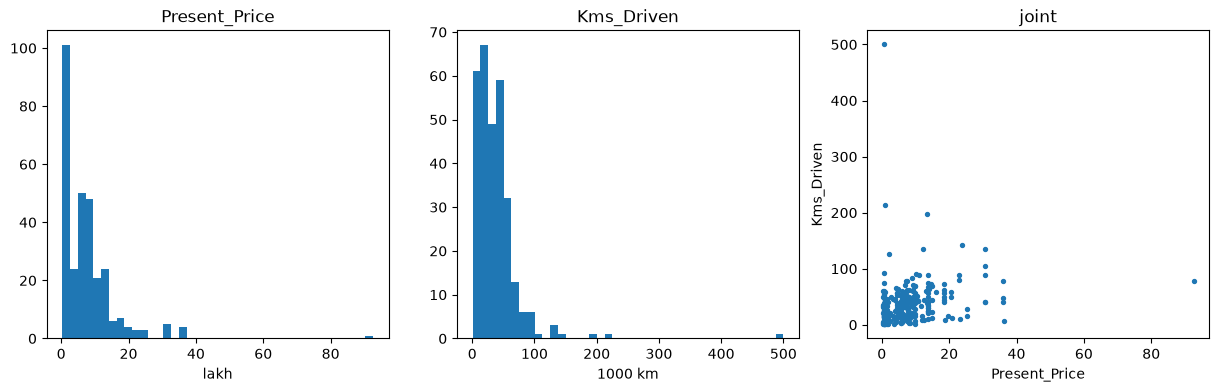

In [4]:
car = pd.DataFrame({'Present_Price': car_sale_data['Present_Price'],
                    'Kms_Driven': car_sale_data['Kms_Driven'] / 1000})   # thousands of km
print(car.describe().round(1))

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
axs[0].hist(car['Present_Price'], bins=40); axs[0].set(title='Present_Price', xlabel='lakh')
axs[1].hist(car['Kms_Driven'], bins=40); axs[1].set(title='Kms_Driven', xlabel='1000 km')
axs[2].scatter(car['Present_Price'], car['Kms_Driven'], s=8)
axs[2].set(title='joint', xlabel='Present_Price', ylabel='Kms_Driven')
plt.show()

## Choosing the grid

Both columns are strongly **skewed**: most cars cost under 24 lakh and have under 80 000 km,
but a few extreme values stretch the range to 92 lakh and 500 000 km.  Stretching the grid to
cover them would leave almost every grid cell empty.  So we

* keep the **central ~95 %** of the data: bounds $[0, 24]$ lakh × $[0, 80]$ thousand km;
* use **2 qubits per column** – a 4 × 4 grid.  With only ~280 samples, a finer grid would
  leave many cells with no data at all and make the target distribution very noisy.

In [5]:
bounds = [[0., 24.], [0., 80.]]
num_qubits = [2, 2]
real_data = car[['Present_Price', 'Kms_Driven']].to_numpy()

grid_elements, prob_data = discretize(real_data, bounds, num_qubits)
inside = np.all((real_data >= np.array(bounds)[:, 0]) & (real_data <= np.array(bounds)[:, 1]), axis=1)
print(f"{inside.sum()} of {len(real_data)} cars lie inside the bounds")
print("Present_Price grid:", np.unique(grid_elements[:, 0]).round(1))
print("Kms_Driven grid   :", np.unique(grid_elements[:, 1]).round(1))

277 of 301 cars lie inside the bounds
Present_Price grid: [ 0.  8. 16. 24.]
Kms_Driven grid   : [ 0.  26.7 53.3 80. ]


## Training (about 5 minutes)

training time: 2.3 min,  final relative entropy: 0.1626


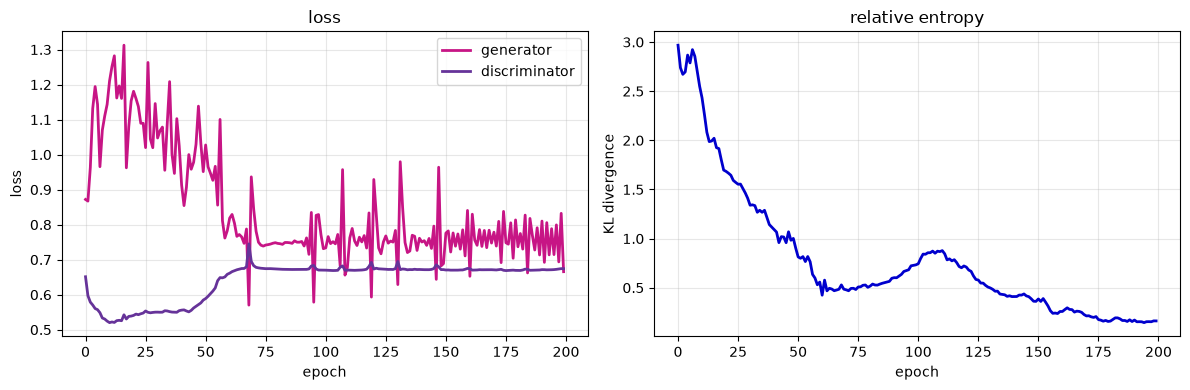

In [6]:
qc = generator_circuit(num_qubits, reps=1)
generator = make_generator(qc, seed=42)
discriminator = Discriminator(input_size=2)

start = time.time()
history = train_qgan(generator, discriminator, grid_elements, prob_data, num_epochs=200)
print(f"training time: {(time.time() - start) / 60:.1f} min,  final relative entropy: {history['rel_entr'][-1]:.4f}")
plot_history(history)

## Result

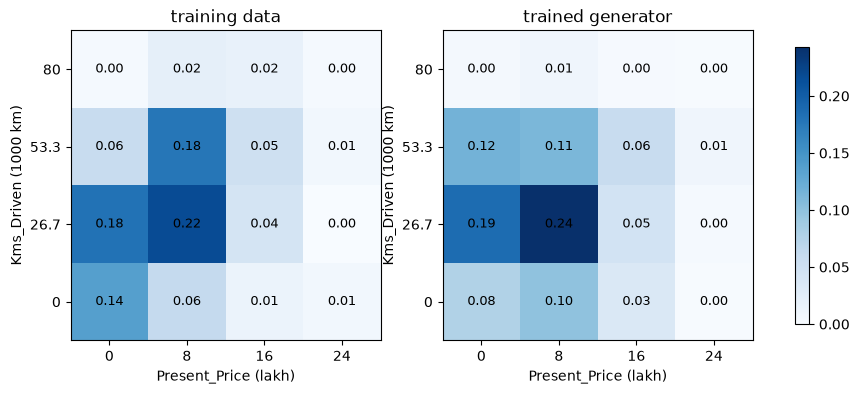

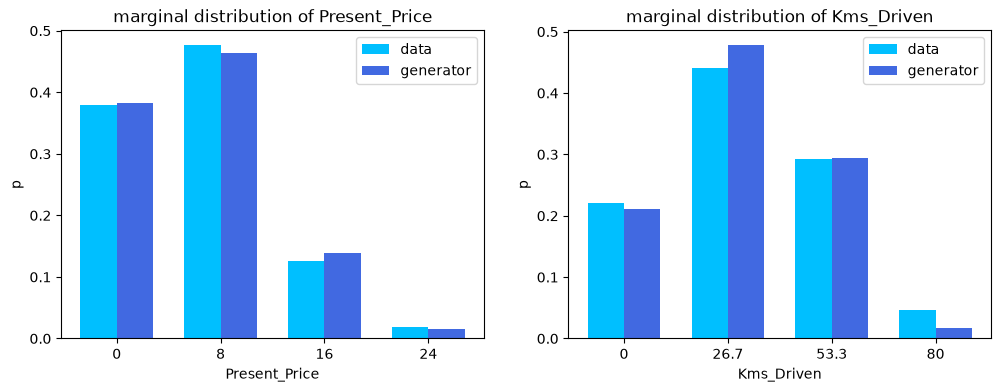

In [7]:
prob_gen = generated_distribution(generator)
show_2d(prob_data, prob_gen, grid_elements, num_qubits, ('Present_Price (lakh)', 'Kms_Driven (1000 km)'))

# rows of the reshaped table = Kms_Driven values, columns = Present_Price values
n0 = 2 ** num_qubits[0]
table_data, table_gen = prob_data.reshape(-1, n0), prob_gen.reshape(-1, n0)
marginals = {'Present_Price': (table_data.sum(axis=0), table_gen.sum(axis=0)),
             'Kms_Driven': (table_data.sum(axis=1), table_gen.sum(axis=1))}

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, axis, name in zip(axs, (0, 1), ('Present_Price', 'Kms_Driven')):
    values = np.unique(grid_elements[:, axis])
    marg_data, marg_gen = marginals[name]
    width = 0.35 * (values[1] - values[0])
    ax.bar(values - width / 2, marg_data, width=width, label='data', color='deepskyblue')
    ax.bar(values + width / 2, marg_gen, width=width, label='generator', color='royalblue')
    ax.set_xticks(values, [f'{v:.3g}' for v in values])
    ax.set(title=f'marginal distribution of {name}', xlabel=name, ylabel='p'); ax.legend()
plt.show()

## Discussion
* The generator reproduces the main features: most cars cost under ~12 lakh and have been
  driven roughly 20 000–60 000 km; expensive cars are rare.
* Rare combinations (e.g. very high mileage) are the hardest to get right – they carry little
  weight in the loss.  With only ~280 samples, the target distribution is itself noisy.
* Data preparation (bounds, resolution) mattered as much as the model.

## Try it yourself
1. Use `num_qubits = [3, 2]` (an 8 × 4 grid).  Does the relative entropy get better or worse?  Why?
2. Learn `Present_Price` vs `Selling_Price` instead – two strongly correlated columns.
3. Try `generator_circuit(num_qubits, reps=2)` and 300 epochs.

**Next:** `424-QGAN-05-Option-Pricing` – putting a trained generator to work.